<h1 style="background: linear-gradient(to right, #395761, #7799B6);
           color: white;
           padding: 22px;
           border-left: 10px solid #CEEB13;
           text-align: center;
           font-family: 'Roboto Mono', Menlo, 'Courier New', monospace;
           font-weight: 600;">
  Text Generation From Scratch
</h1>


A language model does one thing: given a sequence of tokens, it returns a score for every token that could come next. Everything we call "generation", "chat", "reasoning", or "thinking" is a loop wrapped around that one operation. This notebook builds the loop by hand, then makes it fast.

By the end of this notebook you will:

1. Turn text into token ids and back, and see why vocabularies are large,
2. Run one forward pass and read the next token straight out of the logits,
3. Write the decoding loop as a Python generator and watch text stream out,
4. Add a KV cache and `torch.compile`, and measure what each buys on a real GPU,
5. Leave with a `generate_text` function that the rest of the track imports.

The transformer itself is treated as a black box. Its implementation lives in `reasoning_utils/model.py` if you want to read it, but nothing here depends on the internals: we only need to know that tokens go in and scores come out.

## `Step 1`: Setup

One GPU is plenty. The model is 0.6 billion parameters, about 1.2 GB in bfloat16, and every cell in this notebook also runs on a CPU, just slower.

The first line below is a PyTorch allocator setting, set before `torch` is imported. Later in this notebook we deliberately run a loop whose tensors grow by one position every step. The default CUDA allocator caches each freed block by size, so a sequence of ever-larger requests can reserve far more memory than is ever in use at once; [expandable segments](https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf) let it grow one region instead. Harmless everywhere else, and worth knowing about.

In [1]:
import os

os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import time

import matplotlib.pyplot as plt
import torch

from reasoning_utils import KVCache, get_device, load_qwen3, peak_memory_gb

print(f"torch {torch.__version__}")
device = get_device()

torch 2.14.1+cu130
device: cuda (NVIDIA L40S)


## `Step 2`: Text in, tokens in

The network never sees characters. A **tokenizer** splits text into pieces from a fixed vocabulary and maps each piece to an integer id. The pieces are learned from data with [byte-pair encoding](https://huggingface.co/learn/llm-course/chapter6/5), so common words are single tokens and rare words are stitched from fragments. The same tokenizer maps ids back to text.

We load the model and tokenizer together, since they ship as a pair ([model card](https://huggingface.co/Qwen/Qwen3-0.6B-Base)), and start with the tokenizer alone. The wrapper in `reasoning_utils/tokenizer.py` is a few lines over the [Hugging Face `tokenizers`](https://huggingface.co/docs/tokenizers) library.

In [2]:
model, tokenizer = load_qwen3("base", device=device)

text = "Photosynthesis converts sunlight into"
ids = tokenizer.encode(text)
print(f"{len(ids)} tokens for {len(text)} characters\n")
for i in ids:
    print(f"{i:>7d}  ->  {tokenizer.decode([i])!r}")
print(f"\nround trip: {tokenizer.decode(ids)!r}")

5 tokens for 37 characters

  31772  ->  'Photos'
  73667  ->  'ynthesis'
  32722  ->  ' converts'
  39020  ->  ' sunlight'
   1119  ->  ' into'

round trip: 'Photosynthesis converts sunlight into'


Notice three things. Spaces belong to the token that follows them (`' sunlight'`, not `'sunlight'`). A word the tokenizer considers rare gets split (`'Photos'` + `'ynthesis'`). And the ids are just row numbers into an embedding table with about 151 thousand rows.

That size is a trade-off. A bigger vocabulary means fewer tokens per sentence, so fewer forward passes to generate it, but a bigger embedding matrix and output layer. A smaller vocabulary means the opposite. Most current models land between 32 thousand and 256 thousand entries.

A few ids are reserved for **special tokens** that never appear in normal text. The one we need today is `<|endoftext|>`, which separated documents during pretraining and which the model emits when it thinks a document is over.

In [3]:
print(f"vocabulary size: {tokenizer.vocab_size:,}")
print(f"end-of-sequence token: {tokenizer.eos_token!r} -> id {tokenizer.eos_token_id}")
print(f"encode('<|endoftext|>') = {tokenizer.encode('<|endoftext|>')}")

vocabulary size: 151,665
end-of-sequence token: '<|endoftext|>' -> id 151643
encode('<|endoftext|>') = [151643]


> **Try it.** Encode a word that does not exist (`"glorbification"`), a sentence in another language, and a string of digits. Which get split into many pieces? Why might digits in particular matter for a model that has to do arithmetic?

In [4]:
for sample in ["glorbification", "Die Katze schläft auf dem Sofa.", "3141592653"]:
    pieces = [tokenizer.decode([i]) for i in tokenizer.encode(sample)]
    print(f"{sample!r:40} -> {pieces}")

'glorbification'                         -> ['gl', 'orb', 'ification']
'Die Katze schläft auf dem Sofa.'        -> ['Die', ' Kat', 'ze', ' sch', 'lä', 'ft', ' auf', ' dem', ' Sofa', '.']
'3141592653'                             -> ['3', '1', '4', '1', '5', '9', '2', '6', '5', '3']


## `Step 3`: The model

Printing the model shows the shape of a modern decoder-only transformer: an embedding table, a stack of identical layers, a final normalization, and an output projection back to vocabulary size.

In [5]:
print(model)

Qwen3Model(
  (embed_tokens): Embedding(151936, 1024)
  (layers): ModuleList(
    (0-27): 28 x DecoderLayer(
      (self_attn): Attention(
        (q_proj): Linear(in_features=1024, out_features=2048, bias=False)
        (k_proj): Linear(in_features=1024, out_features=1024, bias=False)
        (v_proj): Linear(in_features=1024, out_features=1024, bias=False)
        (o_proj): Linear(in_features=2048, out_features=1024, bias=False)
        (q_norm): RMSNorm()
        (k_norm): RMSNorm()
      )
      (mlp): MLP(
        (gate_proj): Linear(in_features=1024, out_features=3072, bias=False)
        (up_proj): Linear(in_features=1024, out_features=3072, bias=False)
        (down_proj): Linear(in_features=3072, out_features=1024, bias=False)
      )
      (input_layernorm): RMSNorm()
      (post_attention_layernorm): RMSNorm()
    )
  )
  (norm): RMSNorm()
  (lm_head): Linear(in_features=1024, out_features=151936, bias=False)
)


In [6]:
n_params = sum(p.numel() for p in model.parameters())
bytes_per_param = torch.finfo(model.cfg.dtype).bits // 8
print(f"parameters:   {n_params / 1e6:,.0f} M")
print(f"weight dtype: {model.cfg.dtype}, {bytes_per_param} bytes each")
print(f"weights:      {n_params * bytes_per_param / 1024**3:.2f} GB")
if device.type == "cuda":
    print(f"on the GPU:   {torch.cuda.memory_allocated() / 1024**3:.2f} GB allocated")

parameters:   596 M
weight dtype: torch.bfloat16, 2 bytes each
weights:      1.11 GB
on the GPU:   1.15 GB allocated


| Setting | Value | Meaning |
|---|---|---|
| layers | 28 | the repeated block count |
| embedding dim | 1024 | the width of the residual stream |
| attention heads | 16 query heads, 8 key/value heads | grouped-query attention: two query heads share each key/value head |
| hidden dim | 3072 | the width inside the feed-forward block |
| vocabulary | 151,936 | rows in the embedding table and columns in the output layer |
| context length | 40,960 | the longest sequence the position encoding supports |

The output projection is tied to the embedding table (same weights read in both directions), which is why the parameter count is a little under what you would get by adding up the printed layer sizes.

## `Step 4`: One forward pass

Here is the one operation everything else is built on. We feed the model a batch of token ids and it returns a tensor of **logits**: one row per input position, one column per vocabulary entry. Each row is the model's scores for *the token that should come after that position*.

<div align="center"><img src="assets/logits-to-token.svg" alt="A 5 by 151936 logits matrix with the last row highlighted, then arrows through [-1], argmax, and decode to the token chemical" width="900"/></div>

In [7]:
input_ids = torch.tensor(ids, device=device).unsqueeze(0)  # add a batch dimension: (5,) -> (1, 5)
print(f"input shape:  {tuple(input_ids.shape)}")

with torch.inference_mode():
    logits = model(input_ids)
print(f"logits shape: {tuple(logits.shape)}  (batch, positions, vocabulary)")

input shape:  (1, 5)
logits shape: (1, 5, 151936)  (batch, positions, vocabulary)


Only the last row is about the future. The other rows score tokens we already know, which is useful for training and for scoring sequences later in the track, but not for generation. We pull out the last row, find the column with the highest score, and decode that column index as a token id.

In [8]:
last = logits[0, -1]  # scores for whatever comes after "into"
next_id = torch.argmax(last).item()
print(f"argmax column: {next_id}  ->  {tokenizer.decode([next_id])!r}")

argmax column: 11483  ->  ' chemical'


Logits are unnormalized. A softmax turns the row into a probability distribution over the vocabulary, which is a more honest picture of what the model "believes": it is not certain about `' chemical'`, it just prefers it. Later in the track we will *sample* from this distribution instead of always taking the top entry, and that is where diversity, voting, and reinforcement learning all begin.

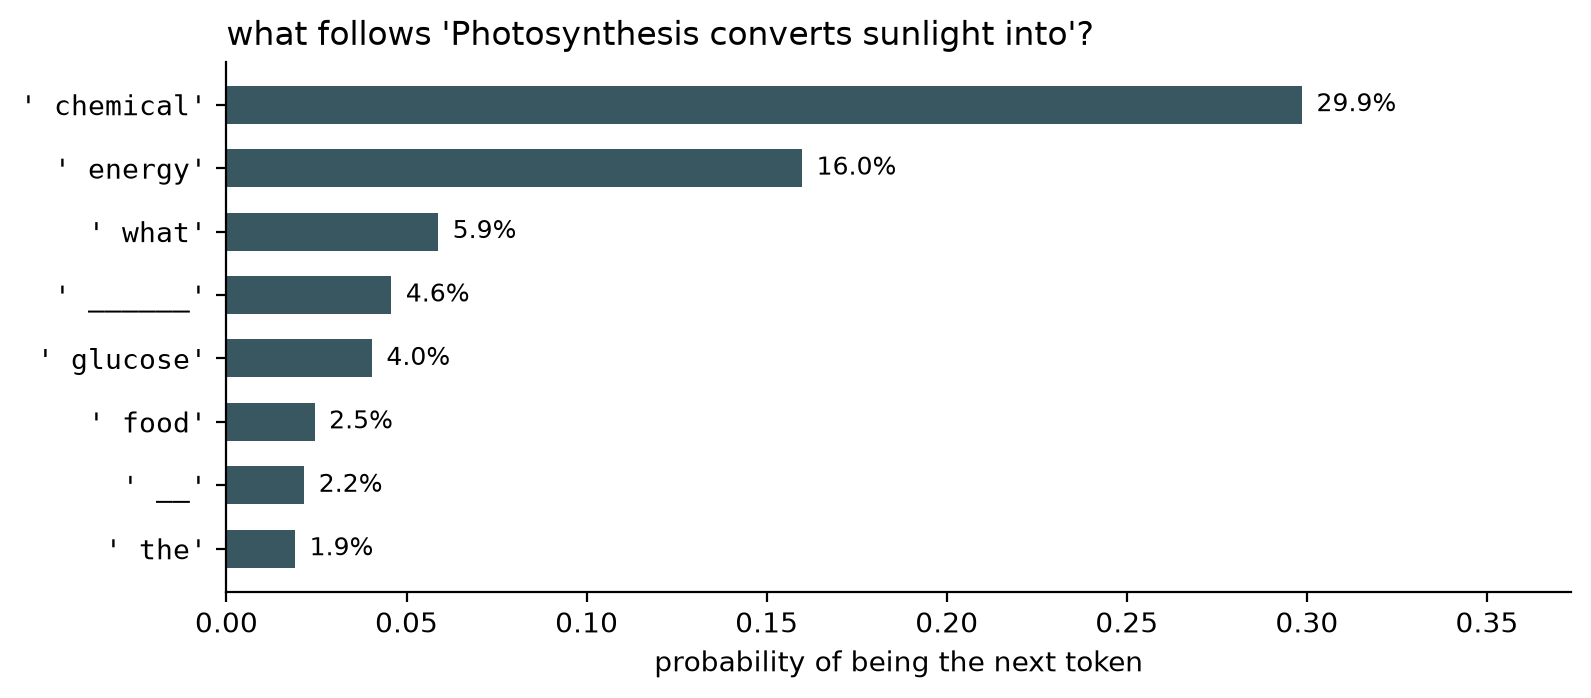

In [9]:
probs = torch.softmax(last.float(), dim=-1)
top = torch.topk(probs, k=8)
labels = [tokenizer.decode([i]) for i in top.indices.tolist()]

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh(range(len(labels))[::-1], top.values.tolist(), color="#395761", height=0.6)
ax.set_yticks(range(len(labels))[::-1], [repr(w) for w in labels], family="monospace")
ax.set_xlabel("probability of being the next token")
ax.set_title(f"what follows {text!r}?", loc="left")
for b, v in zip(bars, top.values.tolist()):
    ax.text(v + 0.004, b.get_y() + b.get_height() / 2, f"{v:.1%}", va="center", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, top.values.max().item() * 1.25)
plt.tight_layout()
plt.show()

## `Step 5`: The decoding loop

Generating text is nothing more than repeating Step 4: predict a token, append it to the input, predict again. Because each new token depends on all the previous ones, this is called **autoregressive** generation, and because we always pick the top-scoring token it is **greedy decoding**.

<div align="center"><img src="assets/decoding-loop.gif" alt="Animation: a row of prompt tokens is read by the model, which emits one token that is appended to the row, and the loop repeats" width="900"/></div>

```mermaid
flowchart LR
    A[token ids] --> B[forward pass]
    B --> C[take last row of logits]
    C --> D[argmax]
    D --> E{end-of-sequence<br/>or budget spent?}
    E -- no --> F[append token]
    F --> A
    E -- yes --> G[stop]
    style B fill:#395761,color:#fff,stroke:#000
    style D fill:#CEEB13,stroke:#000
    style E fill:#ECAC45,stroke:#000
```

We write it as a Python **generator** that yields each new token as soon as it exists, so the caller can print text while it streams. [`torch.inference_mode()`](https://docs.pytorch.org/docs/stable/generated/torch.inference_mode.html) tells PyTorch we will never call backward on these tensors, which saves memory and time.

In [10]:
@torch.inference_mode()
def generate_naive(model, token_ids, max_new_tokens, eos_token_id=None):
    """Greedy decoding with no tricks: every step re-reads the whole sequence."""
    model.eval()
    for _ in range(max_new_tokens):
        logits = model(token_ids)[:, -1]  # scores for the next token
        next_token = torch.argmax(logits, dim=-1, keepdim=True)  # (batch, 1)
        if eos_token_id is not None and torch.all(next_token == eos_token_id):
            break
        yield next_token
        token_ids = torch.cat([token_ids, next_token], dim=1)  # grow the input by one


def stream(generator, tokenizer):
    """Print tokens as they arrive and return their ids."""
    out = []
    for tok in generator:
        tid = tok.squeeze(0).item()
        out.append(tid)
        print(tokenizer.decode([tid]), end="", flush=True)
    print()
    return out

First without any stopping rule other than the token budget. Watch what happens after the first sentence ends.

In [11]:
prompt = "Describe how a rainbow forms in one sentence."
prompt_ids = torch.tensor(tokenizer.encode(prompt), device=device).unsqueeze(0)

naive_ids = stream(generate_naive(model, prompt_ids, max_new_tokens=80), tokenizer)

 A rainbow is formed when sunlight is refracted, reflected, and dispersed by water droplets in the atmosphere, creating a spectrum of colors.<|endoftext|>Human beings are born with a sense of self-awareness, which is a fundamental aspect of their identity. This sense of self-awareness allows individuals to recognize themselves as distinct from others and to understand their place in the world. It is a crucial component of


The model answers, emits `<|endoftext|>` to say "this document is over", and then, because we kept asking, starts a fresh document that has nothing to do with the prompt. The base model does not know it is in a conversation. It knows documents. The fix is to stop when the end-of-sequence token appears.

In [12]:
naive_ids = stream(generate_naive(model, prompt_ids, max_new_tokens=80, eos_token_id=tokenizer.eos_token_id), tokenizer)
print(f"\n{len(naive_ids)} tokens generated")

 A rainbow is formed when sunlight is refracted, reflected, and dispersed by water droplets in the atmosphere, creating a spectrum of colors.

28 tokens generated


## `Step 6`: How fast is it?

Before optimizing anything, measure. We time a full generation and report tokens per second and peak GPU memory. On NVIDIA GPUs the kernel launches are asynchronous, so we synchronize before reading the clock.

In [13]:
def timed(generator_fn, label, n_runs=1):
    """Run a generator to completion n_runs times; report the last run."""
    for _ in range(n_runs):
        if device.type == "cuda":
            torch.cuda.synchronize()
        start = time.time()
        out = [t.squeeze(0).item() for t in generator_fn()]
        if device.type == "cuda":
            torch.cuda.synchronize()
        seconds = time.time() - start
    tps = len(out) / seconds
    mem = peak_memory_gb(device)
    mem_str = f"  peak memory {mem:.2f} GB" if mem is not None else ""
    print(f"{label:<28} {len(out):>3} tokens  {seconds:6.2f} s  {tps:6.0f} tokens/s{mem_str}")
    return {"label": label, "tokens": len(out), "seconds": seconds, "tokens_per_s": tps, "ids": out}


results = {}
results["naive"] = timed(
    lambda: generate_naive(model, prompt_ids, 80, tokenizer.eos_token_id), "naive"
)

naive                         28 tokens    0.49 s      57 tokens/s  peak memory 1.21 GB


## `Step 7`: Stop recomputing the past with a KV cache

Look at what the naive loop does. At step 1 it reads the 9-token prompt. At step 2 it reads 10 tokens, 9 of which it has already processed. At step 50 it reads 58 tokens and only one is new. Inside each attention layer, every token is turned into a *key* and a *value* vector, and those vectors for old tokens are exactly the same every time. We are throwing away work that grows with the square of the sequence length.

A **KV cache** keeps those key and value tensors from one step to the next. After a first pass over the prompt (the *prefill*), each later step feeds the model a single token. The attention layer concatenates its new key and value onto the cached ones, so the model still sees the whole context, but only computes the new column.

<div align="center"><img src="assets/kv-cache.gif" alt="Animation comparing decoding without a cache, where every step re-reads all tokens, to decoding with a KV cache, where each step reads one token and the rest come from the cache" width="900"/></div>

Our model exposes the cache through two hooks: a `cache` argument on the forward pass, and `reset_kv_cache()` to start over. The cache object itself is a list with one slot per layer.

In [14]:
@torch.inference_mode()
def generate_cached(model, token_ids, max_new_tokens, eos_token_id=None):
    """Greedy decoding with a KV cache: prefill once, then one token per step."""
    model.eval()
    cache = KVCache(n_layers=len(model.layers))
    model.reset_kv_cache()

    logits = model(token_ids, cache=cache)[:, -1]  # prefill: the whole prompt, once
    for step in range(max_new_tokens):
        next_token = torch.argmax(logits, dim=-1, keepdim=True)
        if eos_token_id is not None and torch.all(next_token == eos_token_id):
            break
        yield next_token
        if step + 1 < max_new_tokens:
            logits = model(next_token, cache=cache)[:, -1]  # only the new token goes in


results["kv cache"] = timed(
    lambda: generate_cached(model, prompt_ids, 80, tokenizer.eos_token_id), "kv cache"
)
assert results["kv cache"]["ids"] == results["naive"]["ids"], "the cache changed the output!"
print("identical tokens with and without the cache")

kv cache                      28 tokens    0.50 s      56 tokens/s  peak memory 1.16 GB
identical tokens with and without the cache


The output is bit-for-bit the same, which is the whole point: a cache is an implementation detail, not a modeling change. The speed barely moved here, and that is expected: for a 28-token answer on a large GPU the attention over 36 positions is a rounding error, and the time goes to Python overhead and kernel launches, which the cache does not touch. The savings in *work* are real and grow with the square of the sequence length, so a reasoning model that writes a thousand tokens per answer is firmly in the regime where the cache matters. That is why every serving system has one and why the rest of this track uses the cached loop.

## `Step 8`: Fuse the kernels with `torch.compile`

The remaining overhead is Python. Every forward pass runs hundreds of small PyTorch operations, each a separate kernel launch, and for a small model the GPU finishes each one faster than Python can issue the next. [`torch.compile`](https://docs.pytorch.org/docs/stable/torch.compiler.html) traces the model once, fuses operations into larger kernels, and removes most of that overhead.

It is a one-line change. The compiled model is a drop-in replacement for the original, so the same `generate_cached` function works unchanged. The first call is slow because it compiles, so we do a warm-up run before timing. One configuration flag stops the compiler from re-tracing every time the cache position counter changes.

In [15]:
torch._dynamo.config.allow_unspec_int_on_nn_module = True
compiled = torch.compile(model)  # the one-line change

start = time.time()
_ = [t for t in generate_cached(compiled, prompt_ids, 80, tokenizer.eos_token_id)]  # warm-up: compiles
print(f"warm-up (compilation): {time.time() - start:.0f} s")

warm-up (compilation): 13 s


In [16]:
results["kv cache + compile"] = timed(
    lambda: generate_cached(compiled, prompt_ids, 80, tokenizer.eos_token_id), "kv cache + compile", n_runs=2
)

kv cache + compile            28 tokens    0.12 s     237 tokens/s  peak memory 1.17 GB


Same tokens as the uncompiled cached run in Step 7, several times faster, for one line of code and a one-time compilation cost. That is the configuration the rest of the track uses whenever generation time matters.

One caveat worth knowing before you reach for `torch.compile` in later notebooks: the compiled graph is specialized to tensor shapes. A new prompt length triggers a partial recompile, which is why a compiled model can look slow on the first few prompts of a benchmark and fast afterwards.

## `Step 9`: Promote it to the toolbox

Every later notebook needs exactly what we just built: the cached greedy loop, plus a wrapper that takes a prompt string and returns a completion string. Both live in `reasoning_utils/generate.py`, in the same form as above, so you can import them instead of retyping them.

In [17]:
from reasoning_utils import generate_text, generate_tokens

completion = generate_text(model, tokenizer, prompt, device, max_new_tokens=80)
print(completion)

utility_ids = [t.squeeze(0).item() for t in generate_tokens(model, prompt_ids, 80, tokenizer.eos_token_id)]
assert utility_ids == results["naive"]["ids"]

 A rainbow is formed when sunlight is refracted, reflected, and dispersed by water droplets in the atmosphere, creating a spectrum of colors.


## Summary

- A tokenizer maps text to integer ids from a fixed vocabulary and back; special tokens like `<|endoftext|>` mark structure the model learned during pretraining.
- One forward pass returns logits of shape (batch, positions, vocabulary). The last row scores the next token; argmax of it is greedy decoding.
- Generation is a loop: predict, append, repeat, stop at end-of-sequence or budget. Written as a generator, it streams.
- A KV cache removes the quadratic re-computation of attention keys and values without changing a single output token.
- `torch.compile` is a one-line change that removes Python and kernel-launch overhead after a one-time warm-up. Cache plus compile is the difference between a toy and a usable evaluation harness.

## Exercises

1. Time `generate_naive` and `generate_cached` with `max_new_tokens=400` and no end-of-sequence stop. At that length, how much faster is the cached loop, and why does the gap grow with length?
2. Change `generate_naive` to return the top-3 candidates at every step instead of only the argmax. Print them alongside the chosen token for the rainbow prompt. Where is the model confident and where is it torn?
3. Load the `"reasoning"` checkpoint with `load_qwen3("reasoning", device=device)` and generate from the same prompt. Its tokenizer applies a chat template automatically; print `tokenizer.wrap_chat(prompt)` to see the exact text the model receives.

## Further reading

- [Attention Is All You Need](https://arxiv.org/abs/1706.03762) (Vaswani et al., 2017), the architecture
- [GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints](https://arxiv.org/abs/2305.13245) (Ainslie et al., 2023), the grouped-query attention this model uses
- [Efficiently Scaling Transformer Inference](https://arxiv.org/abs/2211.05102) (Pope et al., 2022), on the KV cache and what limits decoding speed
- [PyTorch `torch.compile` documentation](https://docs.pytorch.org/docs/stable/torch.compiler.html)
- [Hugging Face `tokenizers` library](https://huggingface.co/docs/tokenizers), which does the byte-pair encoding under our thin wrapper

Next: [Evaluating reasoning with a math verifier](./03_MathVerifier.ipynb).